# Bayesian Weibull model without covariates

A parametric model assumes a distribution for the survival times. We use the Weibull distribution, check graphically that it is suitable for the data, and estimate its parameters in three ways: with a linear regression on the Kaplan-Meier estimator, by maximum likelihood with `lifelines`, and with a Bayesian model in `pymc`.

The data are the times, in weeks, to discontinuation of the use of an intrauterine device (IUD) for 18 women (`status` is 1 for an observed discontinuation and 0 for a censored time).

In [1]:
import numpy as np
import pandas as pd
import xarray as xr

import pymc as pm
import arviz as az

import statsmodels.api as sm
import pytensor.tensor as pt

import matplotlib.pyplot as plt

from lifelines import KaplanMeierFitter, WeibullFitter
from lifelines.utils import median_survival_times
from ipywidgets import interact, FloatSlider

In [2]:
ALPHA = 0.11 # Significance level for the prediction intervals
SEED = 111   # For reproducible results

T_VECT = np.linspace(0, 140) # Time to evaluate the estimated survivor functions

In [3]:
# Colors shared by all the plots
point_color = '#c1121f'
line_color  = '#1f4e79'
ci_color    = '#7fb8d8'
pi_color    = '#cfe8f3'
opt_color   = '#E69F00'
ref_color   = '#333333'

interval_label = f'{(1 - ALPHA) * 100:.0f}% highest density interval'

## Reading and preprocessing the data

In [4]:
DatOriginal = pd.read_csv("data/iud_discontinuation.dat", sep=r"\s+")

In [5]:
DatOriginal.head()

,time,status
0,10,1
1,13,0
2,18,0
3,19,1
4,23,0


In [6]:
KM = KaplanMeierFitter()
KM.fit(DatOriginal['time'], DatOriginal['status'])

<lifelines.KaplanMeierFitter:"KM_estimate", fitted with 18 total observations, 9 right-censored observations>

## The Weibull distribution

The Weibull distribution with shape $\rho$ and scale $\lambda$ has

$$
S(t)=\exp\left\{-\left(\frac{t}{\lambda}\right)^\rho\right\},\qquad
h(t)=\frac{\rho}{\lambda^\rho}\,t^{\rho-1},\qquad
t(p)=\lambda\{-\log(1-p)\}^{1/\rho}.
$$

The scale $\lambda$ is the time at which 63% of the individuals have had the event. The shape $\rho$ decides how the hazard changes with time: it increases if $\rho>1$, decreases if $\rho<1$, and is constant (exponential distribution) if $\rho=1$.

In [7]:
# Weibull log-survivor function
def WeibullLogSurvivor(t, rho, lam):
    return (-(t/lam)**rho)

# Weibull survivor function
def WeibullSurvivor(t, rho, lam):
    return np.exp(WeibullLogSurvivor(t, rho, lam))

# Weibull hazard function
def WeibullHazard(t, rho, lam):
    return rho / lam**rho * t**(rho-1)

# Time quantile
def TimeQuantile(p, rho, lam):
    return lam * (-np.log(1-p))**(1/rho)

In [8]:
def PlotKm(ax, km_estimate, color=ref_color, label='Kaplan-Meier estimator', band=False):
    # Kaplan-Meier estimator as a step function, with a tick at each censored time
    surv = km_estimate.survival_function_.iloc[:, 0]
    if band:
        ci = km_estimate.confidence_interval_
        ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], step='post', color=color, alpha=0.15, lw=0)
    ax.step(surv.index, surv, where='post', color=color, lw=2, label=label)
    censored = km_estimate.event_table.index[km_estimate.event_table['censored'] > 0]
    ax.plot(censored, surv.loc[censored], '|', color=color, markersize=11, markeredgewidth=2)

def PlotWeibull(axes, rho, lam, color=line_color, label=None):
    # Survivor function (with the Kaplan-Meier estimator of the data) and hazard function of a Weibull distribution
    t = T_VECT[1:]
    axes[0].plot(t, WeibullSurvivor(t, rho, lam), color=color, lw=2, label=label)
    axes[1].plot(t, WeibullHazard(t, rho, lam), color=color, lw=2, label=label)

def FormatWeibull(axes):
    axes[0].set_ylabel('Survivor function')
    axes[0].set_ylim(0, 1.02)
    axes[0].set_title('Survivor function')
    axes[1].set_ylabel('Hazard function')
    axes[1].set_ylim(0, 0.05)
    axes[1].set_title('Hazard function')
    for ax in axes:
        ax.set_xlabel('Time (weeks)')
        ax.set_xlim(0, T_VECT[-1])
        ax.grid(True, alpha=0.25)

Move the sliders to change the parameters and try to follow the Kaplan-Meier estimator of the data (this cell needs a running kernel).

In [9]:
def interactive_weibull(rho, lam):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
    PlotKm(axes[0], KM)
    PlotWeibull(axes, rho, lam, label=fr'Weibull, $\rho$ = {rho:.1f}, $\lambda$ = {lam:.0f}')
    FormatWeibull(axes)
    axes[0].legend(loc='lower left', frameon=False)
    plt.show()

interact(interactive_weibull,
         rho=FloatSlider(value=1, min=0.4, max=3, step=0.1, description='rho'),
         lam=FloatSlider(value=100, min=40, max=160, step=5, description='lambda'));

interactive(children=(FloatSlider(value=1.0, description='rho', max=3.0, min=0.4), FloatSlider(value=100.0, de…

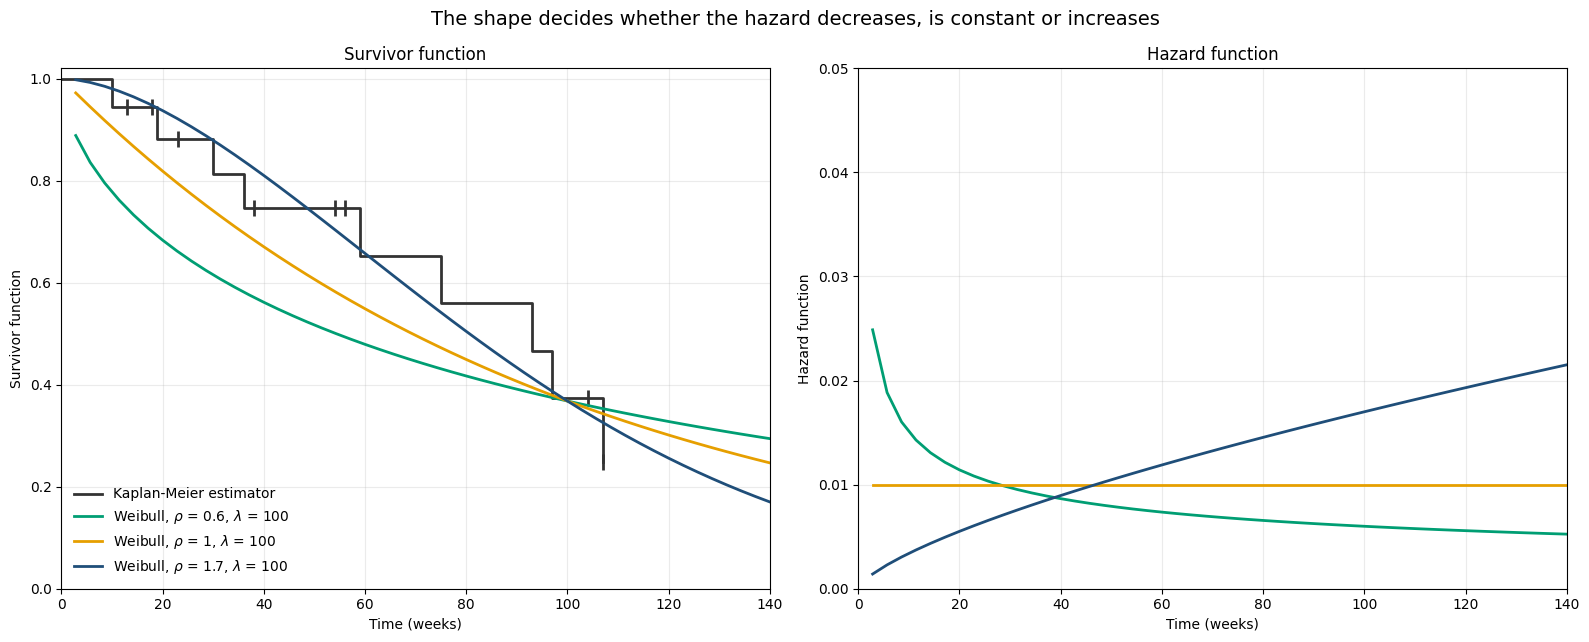

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
PlotKm(axes[0], KM)
for rho, color in zip([0.6, 1, 1.7], ['#009E73', opt_color, line_color]):
    PlotWeibull(axes, rho, 100, color=color, label=fr'Weibull, $\rho$ = {rho}, $\lambda$ = 100')
FormatWeibull(axes)
axes[0].legend(loc='lower left', frameon=False)
fig.suptitle('The shape decides whether the hazard decreases, is constant or increases', fontsize=14)
plt.tight_layout()

## Suitability of Weibull distribution

$$\log(-\log S(t)) = -\alpha\log\beta+\alpha\log t$$

- The points $(\log t_i, \log(-\log\widehat{S}(t_i)))$ should follow a straight line.
- We can implement linear regression: $$\log(-\log\widehat{S}(t_i))=\beta_0+\beta_1\log t_i+\varepsilon,$$
$$\Rightarrow \hat{\beta}=\exp\{-\hat{\beta}_0/\hat{\beta}_1\},\quad \hat{\alpha}=\hat{\beta}_1.$$

(Here $\alpha$ is the shape $\rho$ and $\beta$ is the scale $\lambda$.)

In [11]:
_ = (-np.log(KM.survival_function_['KM_estimate'])).reset_index().drop_duplicates()
_ = _[_["KM_estimate"]>0]

In [12]:
RegModel = sm.OLS(np.log(_['KM_estimate']), sm.add_constant(np.log(_['timeline'])))
RegModelFit = RegModel.fit()

In [13]:
RegModelFit.summary2(alpha=ALPHA)

<class 'statsmodels.iolib.summary2.Summary'>
"""
                 Results: Ordinary least squares
=================================================================
Model:              OLS              Adj. R-squared:     0.945   
Dependent Variable: KM_estimate      AIC:                2.2435  
Date:               2026-10-13 09:34 BIC:                3.7887  
No. Observations:   16               Log-Likelihood:     0.87823 
Df Model:           1                F-statistic:        259.6   
Df Residuals:       14               Prob (F-statistic): 1.97e-10
R-squared:          0.949            Scale:              0.059957
------------------------------------------------------------------
              Coef.   Std.Err.     t      P>|t|    [0.055   0.945]
------------------------------------------------------------------
const        -6.1860    0.3102  -19.9400  0.0000  -6.7154  -5.6566
timeline      1.3223    0.0821   16.1118  0.0000   1.1822   1.4623
-----------------------------------------------------------------
Omnibus:               1.482        Durbin-Watson:          1.644
Prob(Omnibus):         0.477        Jarque-Bera (JB):       1.073
Skew:                  -0.599       Prob(JB):               0.585
Kurtosis:              2.580        Condition No.:          20   
=================================================================
Notes:
[1] Standard Errors assume that the covariance matrix of the
errors is correctly specified.
"""

In [14]:
HatRhoRegression = RegModelFit.params.iloc[1]
HatLambdaRegression = np.exp(-RegModelFit.params.iloc[0]/RegModelFit.params.iloc[1])

round(HatRhoRegression, 4), round(HatLambdaRegression, 4)

(np.float64(1.3223), np.float64(107.5971))

In [15]:
round(TimeQuantile(0.5, HatRhoRegression, HatLambdaRegression), 4)

np.float64(81.5492)

Suitability of log-logistic distribution

For comparison, with a log-logistic distribution the points $(\log t_i, \log[\widehat{S}(t_i)/\{1-\widehat{S}(t_i)\}])$ should follow a straight line.

In [16]:
SurvivorKm = KM.survival_function_['KM_estimate'].reset_index().drop_duplicates()
SurvivorKm = SurvivorKm[(SurvivorKm['KM_estimate'] > 0) & (SurvivorKm['KM_estimate'] < 1)]
LogOdds = np.log(SurvivorKm['KM_estimate'] / (1-SurvivorKm['KM_estimate']))

RegLogLogistic = sm.OLS(LogOdds, sm.add_constant(np.log(SurvivorKm['timeline']))).fit()

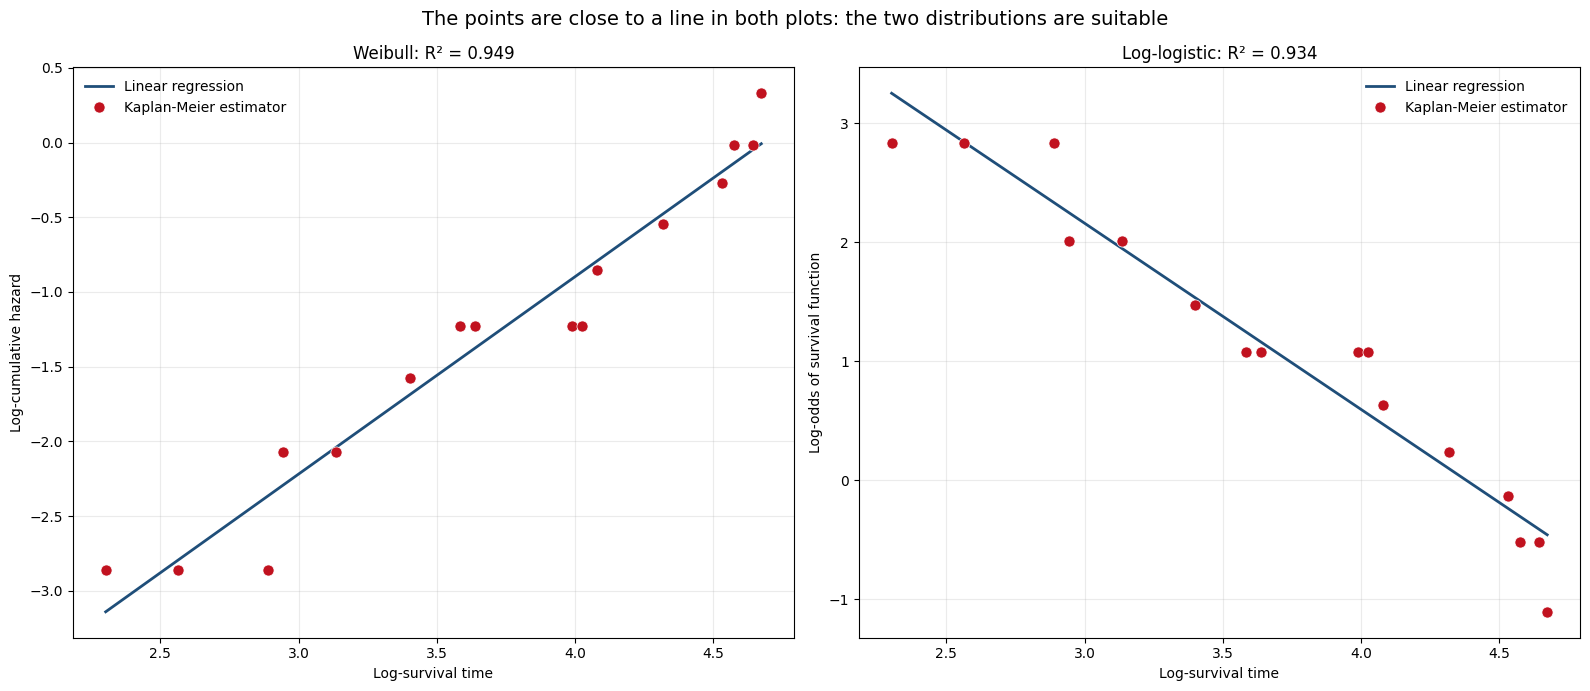

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].plot(np.log(_['timeline']), RegModelFit.fittedvalues, color=line_color, lw=2, label='Linear regression')
axes[0].plot(np.log(_['timeline']), np.log(_['KM_estimate']), 'o', color=point_color, markersize=8, markeredgecolor='white',
             markeredgewidth=0.5, label='Kaplan-Meier estimator')
axes[0].set_ylabel("Log-cumulative hazard")
axes[0].set_title(f'Weibull: R² = {RegModelFit.rsquared:.3f}')

axes[1].plot(np.log(SurvivorKm['timeline']), RegLogLogistic.fittedvalues, color=line_color, lw=2, label='Linear regression')
axes[1].plot(np.log(SurvivorKm['timeline']), LogOdds, 'o', color=point_color, markersize=8, markeredgecolor='white',
             markeredgewidth=0.5, label='Kaplan-Meier estimator')
axes[1].set_ylabel("Log-odds of survival function")
axes[1].set_title(f'Log-logistic: R² = {RegLogLogistic.rsquared:.3f}')

for ax in axes:
    ax.set_xlabel("Log-survival time")
    ax.legend(loc='best', frameon=False)
    ax.grid(True, alpha=0.25)
fig.suptitle('The points are close to a line in both plots: the two distributions are suitable', fontsize=14)
plt.tight_layout()

## Fit the Weibull model using `lifelines`

In [18]:
WeibModel = WeibullFitter()
WeibModel.fit(DatOriginal['time'], DatOriginal['status'])

<lifelines.WeibullFitter:"Weibull_estimate", fitted with 18 total observations, 9 right-censored observations>

In [19]:
WeibModel.print_summary()

<lifelines.WeibullFitter:"Weibull_estimate", fitted with 18 total observations, 9 right-censored observations>
   number of observations = 18
number of events observed = 9
           log-likelihood = -50.35
               hypothesis = lambda_ != 1, rho_ != 1

---
         coef  se(coef)  coef lower 95%  coef upper 95%
lambda_ 98.64     20.16           59.13          138.16
rho_     1.68      0.46            0.77            2.58

         cmp to    z      p  -log2(p)
lambda_    1.00 4.84 <0.005     19.58
rho_       1.00 1.47   0.14      2.82
---
AIC = 104.70

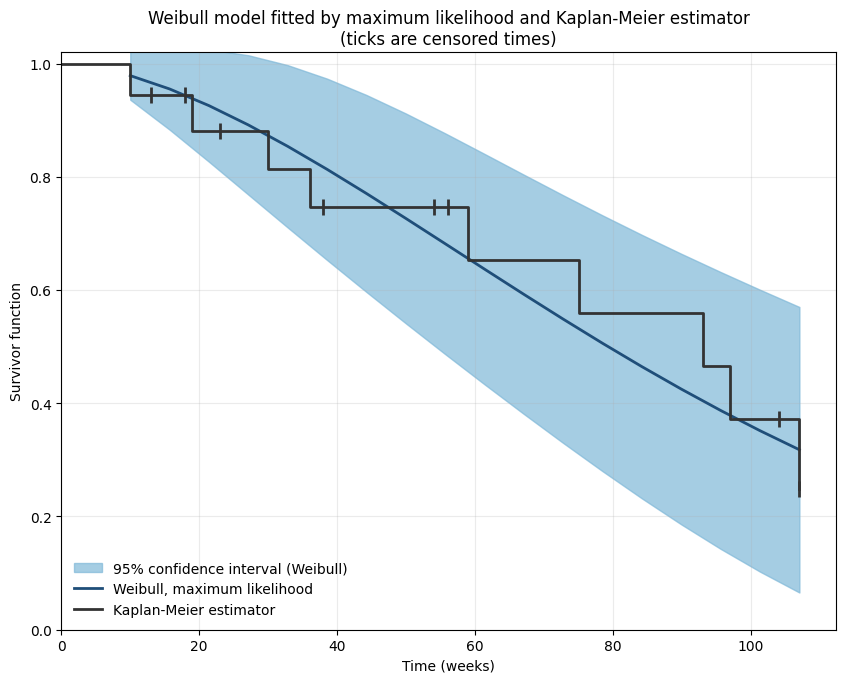

In [20]:
fig, ax = plt.subplots(figsize=(10, 7.5))

ci = WeibModel.confidence_interval_survival_function_
ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color=ci_color, alpha=0.7,
                label='95% confidence interval (Weibull)')
ax.plot(WeibModel.survival_function_.index, WeibModel.survival_function_.iloc[:, 0], color=line_color, lw=2,
        label='Weibull, maximum likelihood')
PlotKm(ax, KM)

ax.set_xlabel("Time (weeks)")
ax.set_ylabel("Survivor function")
ax.set_xlim(0, None)
ax.set_ylim(0, 1.02)
ax.set_title('Weibull model fitted by maximum likelihood and Kaplan-Meier estimator\n(ticks are censored times)')
ax.legend(loc='lower left', frameon=False)
ax.grid(True, alpha=0.25)

In [21]:
WeibModel.median_survival_time_

np.float64(79.27222032047071)

In [22]:
median_survival_times(WeibModel.confidence_interval_)

,Weibull_estimate_lower_0.95,Weibull_estimate_upper_0.95
0.5,10.0,inf


## Fit the Weibull model using Bayesian statistics

$$
\begin{align*}
T|\lambda,\rho &\sim \textsf{Weibull}(\lambda,\rho) \\
\lambda &= \exp\{\mu\} \\
\mu &\sim \textsf{Normal}(0,1) \\
\rho &\sim \textsf{HalfNormal}(5)
\end{align*}
$$

An observed time contributes to the likelihood with the density, and a censored time with the survivor function.

In [23]:
y = DatOriginal["time"].values
ev = (DatOriginal["status"]==1).values

with pm.Model() as WeibullBayesian:
    Mu = pm.Normal("Mu", 0, 1)
    Lambda = pm.Deterministic("Lambda", pt.exp(Mu))
    Rho = pm.HalfNormal("Rho", 5)

    # Time quantile
    MedianTime = pm.Deterministic("MedianTime", TimeQuantile(0.5, Rho, Lambda))

    Logdensity = pm.Weibull("TimesObserved", Rho, Lambda, observed=y[ev])
    Logsurvivor = pm.Potential("TimesCensored", WeibullLogSurvivor(y[~ev], Rho, Lambda))

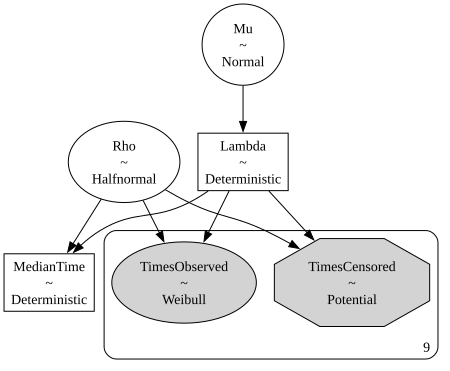

In [24]:
pm.model_to_graphviz(WeibullBayesian)

In [25]:
with WeibullBayesian:
    TraceWeibull = pm.sample(target_accept=0.95, random_seed=SEED)

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [Mu, Rho]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 36 seconds.


In [26]:
az.summary(TraceWeibull, var_names=["Rho", "Lambda", "MedianTime"], kind="stats", hdi_prob=1-ALPHA)

,mean,sd,hdi_5.5%,hdi_94.5%
Rho,1.695,0.447,0.966,2.363
Lambda,87.673,17.132,63.041,113.557
MedianTime,69.752,14.510,46.257,91.331


In [27]:
SummaryMedian = az.summary(TraceWeibull, var_names=["Rho", "Lambda", "MedianTime"], kind="stats", stat_focus="median", hdi_prob=1-ALPHA)
SummaryMedian

,median,mad,eti_5.5%,eti_94.5%
Rho,1.657,0.291,1.043,2.468
Lambda,85.956,10.169,64.328,115.944
MedianTime,69.057,9.207,48.065,93.450


The three estimates of the parameters and of the median time. The Bayesian estimate of $\lambda$, and with it the median, is smaller than the other two: the prior $\mu\sim\textsf{Normal}(0,1)$ puts $\lambda=e^\mu$ around 1, far below the scale of these data, and with only 18 women the prior still pulls the posterior down.

In [28]:
pd.DataFrame(
    {
        'Rho': [HatRhoRegression, WeibModel.rho_, SummaryMedian.loc['Rho', 'median']],
        'Lambda': [HatLambdaRegression, WeibModel.lambda_, SummaryMedian.loc['Lambda', 'median']],
        'MedianTime': [TimeQuantile(0.5, HatRhoRegression, HatLambdaRegression), WeibModel.median_survival_time_,
                       SummaryMedian.loc['MedianTime', 'median']]
    },
    index=['Linear regression', 'Maximum likelihood (lifelines)', 'Bayesian (posterior median)']
).round(3)

,Rho,Lambda,MedianTime
Linear regression,1.322,107.597,81.549
Maximum likelihood (lifelines),1.676,98.644,79.272
Bayesian (posterior median),1.657,85.956,69.057


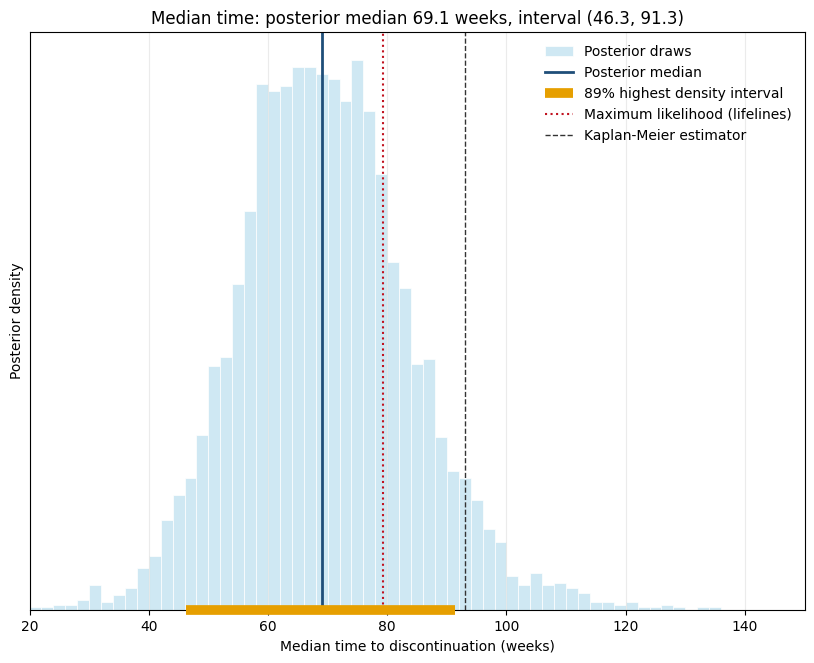

In [29]:
MedianDraws = TraceWeibull.posterior["MedianTime"].to_numpy().ravel()
low, upp = az.hdi(MedianDraws, hdi_prob=1-ALPHA)

fig, ax = plt.subplots(figsize=(10, 7.5))
ax.hist(MedianDraws, bins=np.linspace(20, 150, 66), density=True, color=pi_color, edgecolor='white', linewidth=0.5,
        label='Posterior draws')
ax.axvline(np.median(MedianDraws), color=line_color, lw=2, label='Posterior median')
ax.plot([low, upp], [0, 0], color=opt_color, lw=7, solid_capstyle='butt', clip_on=False, zorder=5, label=interval_label)
ax.axvline(WeibModel.median_survival_time_, color=point_color, lw=1.5, ls=':', label='Maximum likelihood (lifelines)')
ax.axvline(KM.median_survival_time_, color=ref_color, lw=1, ls='--', label='Kaplan-Meier estimator')

ax.set_xlim(20, 150)
ax.set_yticks([])
ax.set_xlabel('Median time to discontinuation (weeks)')
ax.set_ylabel('Posterior density')
ax.set_title(f'Median time: posterior median {np.median(MedianDraws):.1f} weeks, interval ({low:.1f}, {upp:.1f})')
ax.legend(loc='upper right', frameon=False)
ax.grid(True, axis='x', alpha=0.25)

Function to calculate the posterior mean and the credible interval of the survivor function. The function is evaluated at every time for each draw of the posterior distribution.

In [30]:
def CalculateSurvivorFunction(t_vect, trace):
    t = xr.DataArray(t_vect, dims="time", coords={"time": t_vect})
    draws = WeibullSurvivor(t, trace.posterior["Rho"], trace.posterior["Lambda"])
    interval = az.hdi(draws.rename("survivor"), hdi_prob=1-ALPHA)["survivor"]

    return pd.DataFrame(
        {
            "mean": draws.mean(("chain", "draw")).to_numpy(),
            "lower": interval.sel(hdi="lower").to_numpy(),
            "upper": interval.sel(hdi="higher").to_numpy()
        },
        index=t_vect
    )

In [31]:
def PlotSurvivor(survivor, km_estimate):
    fig, ax = plt.subplots(figsize=(10, 7.5))

    ax.fill_between(survivor.index, survivor["lower"], survivor["upper"], color=ci_color, alpha=0.7, label=interval_label)
    ax.plot(survivor.index, survivor["mean"], color=line_color, lw=2, label="Weibull, posterior mean")

    PlotKm(ax, km_estimate, band=True)

    ax.legend(loc='lower left', frameon=False)
    ax.set_xlabel("Time (weeks)")
    ax.set_ylabel("Survivor function")
    ax.set_xlim(0, T_VECT[-1])
    ax.set_ylim(0, 1.02)
    ax.set_title('Bayesian Weibull model and Kaplan-Meier estimator\n(grey band: 95% confidence interval of Kaplan-Meier)')
    ax.grid(True, alpha=0.25)

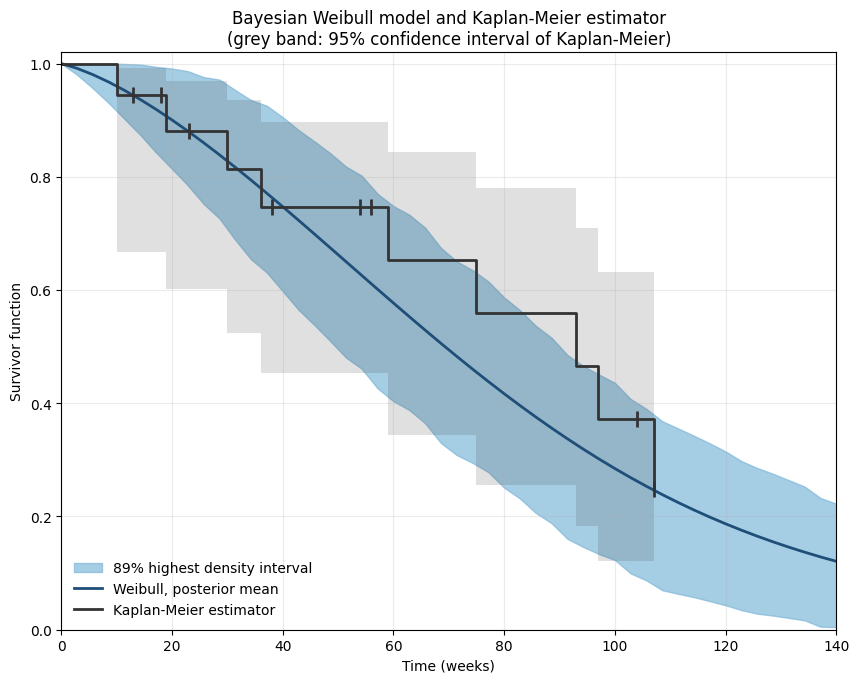

In [32]:
Survivor = CalculateSurvivorFunction(T_VECT, TraceWeibull)
PlotSurvivor(Survivor, KM)